# 从市场 β 到因子 zoo：一本可以独立读完的资产定价导读

**这本导读要回答一个问题：为什么不同资产的平均收益不一样？研究者又怎样用数据检验各种解释？**

读完后你应该能够：

1. 说清收益、超额收益、β、α 这些基本量各是什么，以及它们的单位；
2. 从“投资者只关心整个组合的风险”出发，推出 CAPM 的预期收益公式；
3. 从公司特征（市值、账面市值比、盈利、投资）一步步算出 SMB、HML、RMW、CMA 这些因子收益；
4. 读懂模型检验输出里的 α、$R^2$、t 值、GRS 和 Fama–MacBeth 风险价格；
5. 理解因子越来越多（“factor zoo”）之后，研究者怎样筛选，以及同一套方法怎样迁移到加密资产。

**阅读前提：** 会一点 Python 即可，不需要事先懂金融术语。每个变量都按“定义 → 经济含义 → 为什么选它 → 数值例子或代码”展开；手编的数字都会标明“教学例子”，真实结果都来自本地保存的 French 公开数据。

这本导读自成一体：不需要先运行其他 Notebook。它使用项目里已下载的数据和公共读取函数，不需要联网。

## 阅读路线与运行方式

| 部分 | 要弄懂的问题 |
|---|---|
| [1. 收益与统计记号](#returns) | 收益、超额收益、期望、样本均值、方差、协方差各是什么？ |
| [2. 市场 β 与 CAPM](#capm) | 为什么组合选择会推出“协方差决定预期收益”？β 怎样从数据估计？ |
| [3. 从异象到三因子](#ff3) | 公司的市值、账面市值比怎样变成 SMB、HML 两条收益序列？ |
| [4. 盈利、投资与动量](#ff5) | 为什么又加入盈利和投资？RMW、CMA、动量因子怎样构造？ |
| [5. 怎样检验一个因子模型](#model-tests) | α、$R^2$、t 值、GRS、Fama–MacBeth 各回答什么问题？ |
| [6. 因子 zoo](#zoo) | 候选因子成百上千之后，怎样判断哪个值得保留？ |
| [7. 加密资产支线](#crypto) | 把同一套方法搬到币市，哪些变量需要重新定义？ |

**怎样运行：** 在 VS Code 打开本项目，内核选择 <code>Python (Asset Pricing Quest)</code>
（或解释器 <code>E:/Eth data/asset_pricing_quest/.venv/Scripts/python.exe</code>）。
用 Shift+Enter 逐格执行，或用 Restart Kernel and Run All 从头运行。输出已经保存，不运行也可以直接阅读。

**样本：** 股票实验统一使用 1963-07 至 2013-12 的 606 个月，这正是 Fama–French 2015 年五因子论文的样本期。加密数据是周度的，单独处理，不和月度股票收益混在一起。

In [1]:
# 准备环境：找到项目根目录，导入数据读取和回归汇总工具。这一格还不做任何估计。
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/course.py").exists()), None)
if ROOT is None:
    raise RuntimeError("请从 asset_pricing_quest 文件夹或 notebooks 子目录运行。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from course import load_returns, style, save_table
from analysis import model_summary
style()
print("本地项目：", ROOT)

本地项目： e:\Eth data\asset_pricing_quest


<a id="returns"></a>

## 1. 收益与统计记号

### 1.1 收益与超额收益

先约定下标：$i$ 表示某个资产（一只股票，或一篮子股票组成的组合），$t$ 表示时期（本课多为月份）。

**简单收益率** $R_{i,t}$ 是持有资产 $i$ 一期的回报率。设期初价格 $P_{i,t-1}=100$，期末价格 $P_{i,t}=102$，期末还收到现金股息 $D_{i,t}=1$：

$$R_{i,t}=\frac{P_{i,t}+D_{i,t}}{P_{i,t-1}}-1=\frac{102+1}{100}-1=0.03=3\%.$$

股息也是持有者拿到的回报，所以这叫**总收益**。本课读取的组合收益已经包含股息，直接使用即可。

**无风险收益率** $R_{f,t}$（f 代表 risk-free）是同一期持有几乎没有违约风险的短期国债能得到的回报，实证中用 1 个月美国国库券利率代理。它每个月可以不同。

**超额收益** $R^e_{i,t}=R_{i,t}-R_{f,t}$（e 代表 excess）衡量“承担风险比稳稳拿无风险利息多赚了多少”。资产定价关心的正是这部分：投资者为承担风险要求的补偿。

| 本课读到的数据 | 进入回归前怎么处理 | 回答什么经济问题 |
|---|---|---|
| 股票或组合的总收益 $R_{i,t}$ | 减去当月 `RF` 得到 $R^e_{i,t}$ | 它比无风险资产多赚了多少？ |
| `Mkt-RF`（市场收益减无风险收益） | 已经是超额收益，直接用 | 本月整个股市承担风险的回报是多少？ |
| 因子收益，例如后文的 SMB、HML | 已是“多头组合减空头组合”，直接用 | 本月这个多空方向赚了多少？ |

最后一行的道理：多空组合的两边都含有同一个 $R_{f,t}$，相减时已经抵消，所以不用再减一次。

**单位约定：** 代码内部用月度小数，`0.01` 表示 1%/月，展示时再乘 100。两个收益之差 `0.001` 读作“每月 0.1 个百分点”。比较的收益必须是同一频率、同一月份、同一单位，年收益不能直接放进月度回归。

### 1.2 期望、样本均值、方差与协方差

**期望** $E[\cdot]$ 是总体平均：假如同样的经济环境可以重复很多次，平均会得到多少。$\mu_i^e=E[R_i^e]$ 是资产 $i$ 的**预期超额收益**，也就是资产定价模型要解释的对象。它是看不见的总体量，不是某个月实际拿到的收益。

手里只有 $T$ 个月的数据（$t=1,\ldots,T$），于是用**样本均值**去估计它：

$$\bar R_i^e=\frac1T\sum_{t=1}^T R^e_{i,t}.$$

记号规则：**上横线**表示样本时间平均；**帽子**（如 $\hat\beta_i$、$\hat\alpha_i$）表示从样本估计出的量。样本均值带有抽样误差，样本里平均为正，不代表总体预期一定为正。

**方差**衡量一个收益自身波动多大；**协方差**衡量两个收益是否倾向于同时偏高或同时偏低：

$$
\operatorname{Var}(X)=E[(X-E[X])^2],\qquad
\operatorname{Cov}(X,Y)=E[(X-E[X])(Y-E[Y])].
$$

协方差为正，说明 $X$ 高于均值的月份 $Y$ 也常高于均值；为负则相反。它描述的是“一起动”，不是谁导致谁。

样本版本把期望换成样本均值后求和。之后计算“样本协方差 / 样本方差”时，分子分母用同样的月份和同样的分母（$T$ 或 $T-1$），分母会在比值里约掉。

### 1.3 教学例子：价格涨幅、总收益与超额收益

一股股票月初 100 元、月末 102 元，当月还收到 1 元现金分红；同月无风险收益率为 0.2%。下面把四个量算出来（数字是人为设定的）。

In [2]:
price_start, price_end, dividend = 100.0, 102.0, 1.0
risk_free_return = 0.002
price_return = price_end / price_start - 1
total_return = (price_end + dividend) / price_start - 1
excess_return = total_return - risk_free_return
display(pd.DataFrame({
    "经济量": ["价格涨幅", "含分红总收益", "同期无风险收益", "超额收益"],
    "小数值": [price_return, total_return, risk_free_return, excess_return],
    "百分数（%/月）": np.array(
        [price_return, total_return, risk_free_return, excess_return]) * 100
}).round(4))

,经济量,小数值,百分数（%/月）
0,价格涨幅,0.020,2.0
1,含分红总收益,0.030,3.0
2,同期无风险收益,0.002,0.2
3,超额收益,0.028,2.8


**读数：** 只看价格涨了 2%，加上分红的总收益是 3%，比无风险收益 0.2% 高出 2.8 个百分点，所以超额收益是 2.8%。后面所有股票组合收益都要先减去同月的无风险收益，再进入回归。

<a id="capm"></a>

## 2. 市场 β 与 CAPM

### 2.1 直觉：一项资产怎样改变你已有组合的风险？

投资者最终承担的是**整个持仓**的涨跌，而不是某一只股票的涨跌。设想两只股票自身波动一样大：

- 甲经常在你其他持仓亏钱时也一起亏；
- 乙在你其他持仓亏钱时往往还能赚钱。

把甲加进组合会放大整体风险，把乙加进去则像买了保险。所以，**衡量一项资产的风险，要看它和已有组合的协方差，而不是它自己的方差**。资产自身那些与组合无关的波动，可以靠持有很多资产相互抵消（分散化），不需要补偿。

把这个直觉变成模型，需要四个概念：

- **市场组合**：把所有风险资产按市值比例持有得到的组合。理论上包含全部风险资产；实证中用股票市场指数代理，即数据里的 `Mkt-RF`。
- **均衡**：价格已经调整到位，使得投资者合计想持有的每种资产，恰好等于市场上可供持有的数量（“市场出清”）。
- **被定价**：某种风险暴露越大，模型要求的预期收益补偿就越高。
- **CAPM**（Capital Asset Pricing Model，资本资产定价模型）：Sharpe（1964）、Lintner（1965）、Mossin（1966）提出的均衡模型。它的结论是：**只有与市场组合的协方差被定价**，用 β 衡量。

下面先推导这个结论，再看怎样从数据估计 β。

### 2.2 推导：先求个人最优，再让市场出清

考虑一个**单期**模型：有 $N$ 个风险资产（$i=1,\ldots,N$），以及一个期初就知道收益率 $R_f$ 的无风险资产。先认识记号：

| 记号 | 维度 | 含义 |
|---|---|---|
| $\mu^e$ | $N\times1$ 向量 | 第 $i$ 个元素是 $E[R_i]-R_f$，即各资产的预期超额收益 |
| $\Sigma$ | $N\times N$ 矩阵 | 第 $(i,j)$ 个元素是 $\operatorname{Cov}(R_i,R_j)$；资产之间可以相关，所以通常不是对角矩阵 |
| $w$ | $N\times1$ 向量 | 投到每个风险资产的财富比例，剩余财富放在无风险资产 |
| $w_M$ | $N\times1$ 向量 | 市场组合的权重，元素之和为 1 |
| $R_M=w_M'R$ | 标量 | 市场组合收益；$R$ 是所有 $R_i$ 组成的列向量，撇号 $'$ 表示转置 |
| $\gamma>0$ | 标量 | 风险厌恶系数：投资者对方差的惩罚强度 |

组合的预期超额收益是 $w'\mu^e$，方差是 $w'\Sigma w$。**均值—方差投资者**想要高收益、低方差，可以自由借贷、没有其他约束时，他的问题和一阶条件是

$$
\max_w\;w'\mu^e-\frac{\gamma}{2}w'\Sigma w
\quad\Longrightarrow\quad
\mu^e=\gamma\Sigma w.
$$

这是一个人的最优条件。再加上 CAPM 的假设——所有人预期相同、借贷利率相同——并让市场出清，所有人合计持有的风险组合就必须等于市场组合。于是存在一个共同的比例系数 $\kappa$：

$$\mu^e=\kappa\Sigma w_M.$$

$\Sigma w_M$ 的第 $i$ 项正是 $\operatorname{Cov}(R_i,R_M)$，所以 $\mu_i^e=\kappa\operatorname{Cov}(R_i,R_M)$：**预期超额收益与资产和市场的协方差成正比**。两边左乘 $w_M'$ 得到市场自身 $\mu_M^e=\kappa\operatorname{Var}(R_M)$，消去 $\kappa$：

$$
E[R_i]-R_f
=\underbrace{\frac{\operatorname{Cov}(R_i,R_M)}
{\operatorname{Var}(R_M)}}_{\beta_{i,M}}
\left(E[R_M]-R_f\right).
$$

**怎样读 β：** 分子是资产对市场风险的贡献，除以市场方差后，市场自己的 β 正好等于 1。β = 1.5 意味着这项资产承担的市场风险是市场平均水平的 1.5 倍。

**数值例子：** 年无风险收益率 2%，市场预期超额收益 6%，β = 1.5 的资产在 CAPM 下预期年收益为 $2\%+1.5\times6\%=11\%$。这是模型要求的预期回报，某一年的实际收益仍会围绕它上下波动。

注意，只有一个风险方向被定价，并不是说每只资产只受一种冲击——它还有大量自身特有的波动，只是这些波动可以被分散掉，所以不获得补偿。

延伸阅读：[Markowitz（1952）](https://doi.org/10.1111/j.1540-6261.1952.tb01525.x)、[Sharpe 1964 原文](https://doi.org/10.1111/j.1540-6261.1964.tb02865.x)、[Sharpe 的作者回顾](https://web.stanford.edu/~wfsharpe/art/djam/djam)。

### 2.3 回归形式：β、α 与 ε 各是什么

CAPM 讲的是预期收益。为了用每月数据检验它，把资产超额收益对市场超额收益做线性分解：

$$
R^e_{i,t}=\alpha_i+\beta_iR^e_{M,t}+\varepsilon_{i,t},\qquad
\beta_i=\frac{\operatorname{Cov}(R^e_i,R^e_M)}{\operatorname{Var}(R^e_M)},\qquad
\alpha_i=\mu_i^e-\beta_i\mu_M^e.
$$

其中 $R^e_{M,t}$ 是市场超额收益，$\mu_M^e$ 是它的期望。三个部分的含义：

- **$\beta_i$（斜率）**：市场超额收益每多 1 个百分点，该资产超额收益平均多 $\beta_i$ 个百分点。它衡量**跟着市场一起动的程度**，与资产自身总波动是两回事。
- **$\alpha_i$（截距）**：资产的预期超额收益里，**市场风险补偿 $\beta_i\mu_M^e$ 解释不了的部分**，可以理解为模型的“定价误差”。
- **$\varepsilon_{i,t}$（误差）**：当月偏离这条线的部分。按构造，它平均为零，并且与市场收益不相关；但不同资产的误差之间可以相关。

由此得到关键区分：**任何资产都能算出一个 β，这只是统计；CAPM 的经济含义在于它额外要求 $\alpha_i=0$**，即市场 β 足以解释全部预期超额收益。检验 CAPM，就是检验截距是否为零。

一个容易混淆的历史细节：Sharpe（1963）的“单指数模型”也写成这条回归，但目的是简化组合计算中的协方差；Sharpe（1964）的 CAPM 才从均衡推出 $\alpha_i=0$ 这条定价限制。

### 2.4 OLS：怎样用有限样本画出这条线

**OLS**（ordinary least squares，普通最小二乘）选择截距和斜率，使所有月份的预测误差平方和最小：

$$
(\hat\alpha_i,\hat\beta_i)
=\arg\min_{a,b}\sum_{t=1}^T(R^e_{i,t}-a-bR^e_{M,t})^2.
$$

$a,b$ 是尝试的截距和斜率，$\arg\min$ 表示“取使目标最小的那组参数”。拟合值 $\hat R^e_{i,t}=\hat\alpha_i+\hat\beta_iR^e_{M,t}$，**残差** $\hat\varepsilon_{i,t}=R^e_{i,t}-\hat R^e_{i,t}$。取平方是为了让正负误差不能互相抵消，并对大误差惩罚更重。

求解一阶条件，得到

$$
\hat\beta_i=
\frac{\sum_{t=1}^T(R^e_{M,t}-\bar R_M^e)(R^e_{i,t}-\bar R_i^e)}
     {\sum_{t=1}^T(R^e_{M,t}-\bar R_M^e)^2},\qquad
\hat\alpha_i=\bar R_i^e-\hat\beta_i\bar R_M^e.
$$

第一式就是样本协方差除以样本方差，所以“协方差 / 方差”“手算 OLS”“软件 OLS”三种算法必然给出同一个 β——下一节用真实数据验证。

第二式值得记住：**样本平均超额收益 = 截距 + β × 市场平均超额收益**。这让截距可以直接读成“平均收益中市场没解释的部分”。例如 $\hat\alpha_i=0.001$ 表示每月 0.1 个百分点的未解释平均超额收益。它能否与零区分，要看它的标准误（第 5 部分）。

另外，OLS 残差的样本均值总是零，这是算法的性质；**残差均值为零不等于截距为零**，两者别混淆。

<a id="real-data"></a>

### 2.5 读入真实数据：每个文件、每一列是什么

现在换成真实数据。`load_returns` 读取已经下载到本地的 French 官方数据：它先核对文件的哈希值（确认文件没被改动），再挑出月度收益表，把缺失标记转成空值，并把原文件的百分数转成小数（原文 2.50 读成 0.025）。

| Python 对象／列 | 含义、单位与用途 |
|---|---|
| <code>ff3</code> | 三因子文件：一行一个月，收益为小数 |
| <code>Mkt-RF</code> | 美国股票市场组合（按市值加权）当月收益减无风险收益，代表整个股市的共同涨跌 |
| <code>SMB</code>、<code>HML</code> | 规模因子和价值因子，第 3 部分会从头构造它们；这一节先不用 |
| <code>RF</code> | 当月无风险收益率（1 个月国库券），用来把总收益换成超额收益 |
| <code>portfolios</code> | 25 个“规模 × 账面市值比”组合的月度总收益。每列是一篮子股票，不是一家公司 |
| <code>excess</code> | 上面 25 个组合逐月减去 RF 后的超额收益，作为回归左边要解释的**测试资产** |
| <code>START</code>、<code>END</code> | 样本起止月份。模型比较必须在同一样本上进行 |

**测试资产**是用来检验模型的一组资产：如果模型对，它们的 α 都应接近零。用组合而不是单只股票，是因为组合的特有噪声被平均掉了，平均收益估得更准。25 组合按市值分 5 档、按账面市值比分 5 档，交叉得到 25 篮子（具体分组规则见第 3 部分）。列名 <code>SMALL LoBM</code> 表示“市值最小、账面市值比最低”的那一篮子。

In [3]:
START, END = "1963-07", "2013-12"
ff3 = load_returns("ff3", START, END)
portfolios = load_returns("bm25", START, END)
assert ff3.index.equals(portfolios.index) and len(ff3) == 606
excess = portfolios.sub(ff3["RF"], axis=0)
assert np.isfinite(excess.to_numpy(dtype=float)).all()
factor_labels = {
    "Mkt-RF": "市场超额收益（%/月）", "SMB": "规模因子（%/月）",
    "HML": "价值因子（%/月）", "RF": "无风险收益（%/月）"}
display((ff3.head(4) * 100).rename(columns=factor_labels).round(3))
display(pd.DataFrame({
    "对象": ["因子与无风险收益表", "25个测试组合"],
    "月份数": [len(ff3), len(excess)],
    "列数": [ff3.shape[1], excess.shape[1]],
    "起始月份": [str(ff3.index[0])] * 2,
    "结束月份": [str(ff3.index[-1])] * 2
}))

,市场超额收益（%/月）,规模因子（%/月）,价值因子（%/月）,无风险收益（%/月）
month,,,,
1963-07,-0.39,-0.57,-0.84,0.27
1963-08,5.08,-0.95,1.72,0.25
1963-09,-1.57,-0.25,-0.02,0.27
1963-10,2.54,-0.57,-0.03,0.29


,对象,月份数,列数,起始月份,结束月份
0,因子与无风险收益表,606,4,1963-07,2013-12
1,25个测试组合,606,25,1963-07,2013-12


### 2.6 实验 A：同一个 β，三种算法

取“小规模、低账面市值比”组合（<code>SMALL LoBM</code>）作资产，用官方 `Mkt-RF` 作市场代理，分别用 2.4 节的三种方法计算 β：协方差 / 方差、中心化后的内积、带截距的 OLS。

因为实际的 RF 每月都在变，这里两边都用**超额收益**。三种方法使用同样的月份和同样的分母，所以结果应当完全一致。

,beta
Cov / Var,1.4319
中心化内积,1.4319
含截距 OLS,1.4319


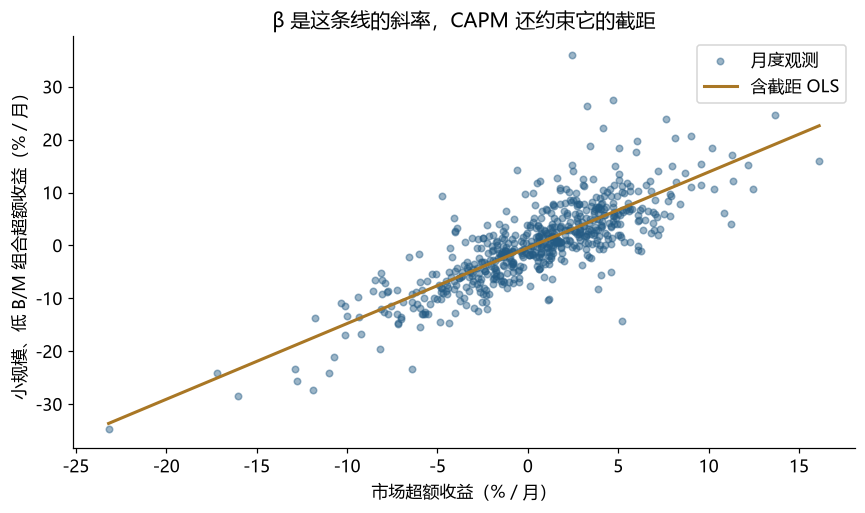

三种算法给出同一个 β = **1.4319**：市场每多涨 1 个百分点，这个组合平均多涨约 1.43 个百分点。截距为 **-0.4479% / 月**，是市场风险解释不了的平均超额收益；按 CAPM 它应为零。$R^2$ 为 **0.6449**，表示这个组合每月的波动中约 64% 能由市场同步涨跌解释。

In [4]:
ASSET = "SMALL LoBM"
# x 是市场超额收益，y 是待解释的组合超额收益，均为月度小数。
x = ff3["Mkt-RF"].to_numpy(dtype=float)
y = excess[ASSET].to_numpy(dtype=float)
# ddof=1 表示协方差和方差都用 T-1 作分母；比值不受共同分母影响。
beta_cov = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)
xc, yc = x-x.mean(), y-y.mean()
beta_centered = np.dot(xc, yc) / np.dot(xc, xc)
# add_constant 添加截距列；OLS 选择截距和斜率以最小化残差平方和。
fitted = sm.OLS(y, sm.add_constant(x)).fit()
beta_ols = float(fitted.params[1])
assert np.allclose([beta_cov, beta_centered], beta_ols, rtol=1e-12, atol=1e-12)
beta_check = pd.DataFrame({"beta": [beta_cov, beta_centered, beta_ols]},
                         index=["Cov / Var", "中心化内积", "含截距 OLS"])
display(beta_check.round(10))
save_table(beta_check, "PRELUDE_beta_identity")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(x*100, y*100, s=18, alpha=0.45, color="#245b84", label="月度观测")
grid = np.linspace(x.min(), x.max(), 100)
ax.plot(grid*100, (fitted.params[0]+beta_ols*grid)*100,
        color="#a97725", linewidth=2, label="含截距 OLS")
ax.set_xlabel("市场超额收益（% / 月）")
ax.set_ylabel("小规模、低 B/M 组合超额收益（% / 月）")
ax.set_title("β 是这条线的斜率，CAPM 还约束它的截距")
ax.legend()
fig.tight_layout()
plt.show()
display(Markdown(
    f"三种算法给出同一个 β = **{beta_ols:.4f}**：市场每多涨 1 个百分点，这个组合平均多涨约 {beta_ols:.2f} 个百分点。"
    f"截距为 **{fitted.params[0]*100:.4f}% / 月**，是市场风险解释不了的平均超额收益；按 CAPM 它应为零。"
    f"$R^2$ 为 **{fitted.rsquared:.4f}**，表示这个组合每月的波动中约 {fitted.rsquared:.0%} 能由市场同步涨跌解释。"))

### 2.7 1952—1979：从单一市场风险到多种风险来源

CAPM 之后，理论和检验并行推进。下表是主线：

| 文献 | 推进的问题 | 阅读要点 |
|---|---|---|
| [Markowitz 1952](https://doi.org/10.1111/j.1540-6261.1952.tb01525.x) | 组合如何权衡均值与方差？ | 风险取决于协方差 |
| [Tobin 1958](https://doi.org/10.2307/2296205) | 加入无风险资产后怎样配置？ | 分离定理：先选同一个风险组合，再按风险承受力和无风险资产混合 |
| [Sharpe 1963](https://doi.org/10.1287/mnsc.9.2.277) | 怎样降低组合计算的维度？ | 单指数统计模型 |
| [Sharpe 1964](https://doi.org/10.1111/j.1540-6261.1964.tb02865.x)、[Lintner 1965](https://doi.org/10.2307/1924119)、[Mossin 1966](https://doi.org/10.2307/1910098) | 市场出清时，什么风险获得报酬？ | CAPM：预期收益与 β 成正比 |
| [Black–Jensen–Scholes 1972](https://ssrn.com/abstract=908569) | 怎样用数据检验 CAPM？ | 按 β 排序成组合，再做回归 |
| [Fama–MacBeth 1973](https://doi.org/10.1086/260061) | 怎样估计风险价格及其误差？ | 每月一次横截面回归，再对系数取时间平均（见 5.5 节） |
| [Merton 1973](https://doi.org/10.2307/1913811) | 投资者还想对冲未来机会变坏怎么办？ | ICAPM：状态变量带来额外的风险因子 |
| [Ross 1976](https://doi.org/10.1016/0022-0531(76)90046-6) | 多个共同收益方向受什么约束？ | APT：无套利推出预期收益与多个暴露近似线性 |
| [Breeden 1979](https://doi.org/10.1016/0304-405X(79)90016-3) | 风险怎样联系到消费？ | 消费 β |

表中三个多因子理论各自回答“除了市场，还可能有什么风险被定价”：

| 模型 | 关键变量 | 为什么会产生额外因子 |
|---|---|---|
| **ICAPM**（Intertemporal CAPM，跨期资本资产定价模型） | **状态变量**：预示未来投资机会好坏的经济状态，例如未来利率或预期回报 | 投资者不只关心本期财富，还关心未来能否以好条件投资。能在机会变坏时提供回报的资产有对冲价值，所以对状态变量的暴露也会被定价 |
| **APT**（Arbitrage Pricing Theory，套利定价理论） | **共同因子**：许多资产一起变动的方向；**暴露**：资产对每个方向的敏感度 | 个别风险能被分散，而共同因子不能；不存在套利机会时，预期收益近似是各暴露的线性函数。理论本身不规定因子具体是什么 |
| **CCAPM**（Consumption-based CAPM，基于消费的资本资产定价模型） | **消费增长** $C_{t+1}/C_t-1$，$C_t$ 是实际消费量 | 财富最终用于消费。在消费低迷、额外一元最珍贵时还能赚钱的资产像保险，因此资产与消费的协方差决定补偿 |

所以，多因子思想早于 Fama–French。FF 的贡献在于：用**可观察的公司特征**构造**可复算的组合收益**作为因子，并在大量测试资产上系统检验。

<a id="ff3"></a>

## 3. 从异象到三因子

### 3.1 动机：CAPM 解释不了的平均收益差异

如果 CAPM 成立，把股票按任何**事先可观察的特征**分组，组合之间的平均收益差异都应被 β 差异解释，α 都为零。研究者把违反这一点的系统性规律称为**异象**（anomaly）：控制市场 β 后仍然存在的平均收益差异。

两个最著名的异象：

- **规模效应**：[Banz（1981）](https://doi.org/10.1016/0304-405X(81)90018-0) 发现小市值公司的平均收益高于其市场 β 所能解释的水平。
- **价值效应**：账面市值比高的股票（相对于账面价值“便宜”的股票）平均收益更高。

异象出现后，可能的解释有四类：模型遗漏了某种被定价的风险；市场错误定价；数据或检验方法有问题；纯属样本偶然。Fama–French 的思路是第一种：
[FF1992](https://doi.org/10.1111/j.1540-6261.1992.tb04398.x) 先发现，在横截面上，规模和账面市值比比市场 β 更能区分平均收益；
[FF1993](../papers/ff1993_primary_reference.pdf) 再把这两个特征变成每月可观察的组合收益 SMB、HML，检验它们能否连同市场一起解释其他组合的平均收益。

下面从原材料开始，一步步构造这两个因子。

### 3.2 原材料：账面权益 BE 与市值 ME

一家公司的股东权益有两种量法：会计报表上的账面值，和股票市场给出的价格。

| 符号 | 定义与单位 | 经济含义 |
|---|---|---|
| $BE$：Book Equity，账面普通股权益 | 入门理解：资产减负债后归普通股股东的部分；单位是金额 | 会计记录的净资产，基于历史成本 |
| $P$：Price，股价 | 每股价格；金额/股 | 在市场上买一股要付多少钱 |
| $Q$：Shares Outstanding，发行在外股数 | 股数 | 全部普通股被分成多少股（用 Q 是为了不和资产数 N 混淆） |
| $ME$：Market Equity，股票市值 | $ME=P\times Q$；金额 | 市场为全部普通股权益付的总价。本课说的 **size（规模）就是 ME** |

**为什么同时需要两者？** BE 是会计尺度，ME 是市场愿意付的价格，两者一比就知道股票相对账面是贵还是便宜。单看股价做不到这一点：一股拆两股，股价减半，但公司总市值和贵贱程度都没有变。

正式研究中的 BE 比入门定义更细：French 从股东权益出发，扣除优先股（依次取赎回价值、清算价值或面值），并按数据版本处理递延税和投资税抵免；对 1993 年及以后结束的财年，不再加回递延税项目。所以数据库里随便一列“净资产”并不等于 BE。本课使用 French 已按这些规则加工好的组合，手算例子只用来建立直觉。

来源：[French 变量定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/variable_definitions.html)；[数据修订说明（2016 年 8 月 BE 变化）](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)。

### 3.3 B/M：把价格放到可比较的尺度上

$B/M$（Book-to-Market，账面市值比，也写 $BE/ME$）和中文常说的市净率 $P/B$ 互为倒数：

$$
B/M=\frac{BE}{ME},\qquad P/B=\frac{ME}{BE}=\frac{1}{B/M}.
$$

- **高 B/M**：每付 1 元市场价，买到较多账面权益，即市净率低。这类股票叫 **value（价值股）**。
- **低 B/M**：每付 1 元，买到较少账面权益，即市净率高。这类股票叫 **growth（成长股）**，因为高价格通常反映了市场对其未来增长的乐观预期。

**为什么选 B/M？** 它把市场价格和会计尺度连在一起，而且是一个容易观测的特征。成长预期、经营困境、风险补偿、定价偏差都会影响这个比率——正因如此，它的高平均收益到底来自哪种原因，才成为需要检验的问题。

两个金额要用同一货币和单位；倒数关系要求 BE 为正，FF 的组合也只纳入正 BE 的公司。注意：高 B/M 指“相对账面便宜”，与股价高低无关。

下面用两家虚构公司把这些量算一遍。

In [5]:
# 教学例子（虚构公司）：金额单位为亿元，股数单位为亿股。
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

demo_companies = pd.DataFrame({
    "公司（模拟）": ["甲公司", "乙公司"],
    "股价（元/股）": [10.0, 50.0],
    "股数（亿股）": [1.0, 1.0],
    "BE：账面权益（亿元）": [8.0, 10.0],
}).set_index("公司（模拟）")
demo_companies["ME：市值（亿元）"] = (
    demo_companies["股价（元/股）"] * demo_companies["股数（亿股）"]
)
demo_companies["B/M（倍）"] = (
    demo_companies["BE：账面权益（亿元）"] / demo_companies["ME：市值（亿元）"]
)
demo_companies["P/B（倍）"] = 1.0 / demo_companies["B/M（倍）"]
display(demo_companies.round(3))
assert np.allclose(
    demo_companies["B/M（倍）"] * demo_companies["P/B（倍）"], 1.0
)
display(Markdown(
    "甲的 B/M 为 **0.80**，乙为 **0.20**：每付 1 元市值，分别买到 0.80 元和 0.20 元账面权益。"
    "甲的股价更低，B/M 也更高；但如果甲的股数是乙的 10 倍，股价不变而市值变大，B/M 就会变小。"
    "可见决定 B/M 的是总市值相对账面权益的大小，而不是每股价格。"
))

,股价（元/股）,股数（亿股）,BE：账面权益（亿元）,ME：市值（亿元）,B/M（倍）,P/B（倍）
公司（模拟）,,,,,,
甲公司,10.0,1.0,8.0,10.0,0.8,1.25
乙公司,50.0,1.0,10.0,50.0,0.2,5.00


甲的 B/M 为 **0.80**，乙为 **0.20**：每付 1 元市值，分别买到 0.80 元和 0.20 元账面权益。甲的股价更低，B/M 也更高；但如果甲的股数是乙的 10 倍，股价不变而市值变大，B/M 就会变小。可见决定 B/M 的是总市值相对账面权益的大小，而不是每股价格。

### 3.4 规模 × B/M 的 2×3 分组：S/L、B/H 怎么读

**为什么还要加入规模？** 小市值股票和大市值股票的平均收益差异，CAPM 难以完全解释；规模也可能反映融资难易、流动性和经营风险。FF1993 因此把规模和 B/M 两个特征都转成因子。

问题在于两个特征相关：小公司里价值股可能更多。如果只按 B/M 分组，“价值效应”里会混进“规模效应”。解决办法是**两个维度独立分组，再取交集**：

| 市值类别 | 低 B/M：L（Low） | 中 B/M：N（Neutral） | 高 B/M：H（High） |
|---|---|---|---|
| 小市值：S（Small） | S/L：小盘、低 B/M | S/N：小盘、中 B/M | S/H：小盘、高 B/M |
| 大市值：B（Big） | B/L：大盘、低 B/M | B/N：大盘、中 B/M | B/H：大盘、高 B/M |

每格是一篮子股票。后文 $R_{SL,t}$ 表示 S/L 这一篮子在月份 $t$ 的收益率。两个容易看错的地方：标签中的 B 是 Big（大盘），而 B/M 中的 B 是 Book（账面）；L/H 指 B/M 的高低，而不是当月收益的高低。

来源：[Fama–French 1992](https://doi.org/10.1111/j.1540-6261.1992.tb04398.x)；[Fama–French 1993 原文](../papers/ff1993_primary_reference.pdf)。

### 3.5 实际操作：什么时候分组、用什么断点、怎样加权

French 美国 2×3 组合每年 6 月底分组一次。以第 $y$ 年为例：

1. **准备特征。** B/M 用上一日历年（$y-1$）结束的财年的 BE，除以 $y-1$ 年 12 月底的 ME；规模用 $y$ 年 6 月底的 ME。用上一年的财报，是为了确保 6 月分组时报表已经公布，避免用到当时还不知道的信息（**前视偏差**）。
2. **设断点。** 规模按纽约证券交易所（NYSE）股票 6 月市值的中位数分成 S/B；B/M 按 NYSE 股票的第 30、70 百分位数分成 L/N/H。然后把 NYSE、AMEX、NASDAQ 所有符合条件的股票放进对应格子。只用 NYSE 定断点，是因为 NASDAQ 有大量微型股，如果用全体股票定中位数，“大盘”组里也会挤满小公司。
3. **持有并计算收益。** 从 $y$ 年 7 月持有到 $y+1$ 年 6 月，之后重新分组。每格内部按**市值加权**计算收益。
4. **合成因子。** 用六格的收益按下两节的公式等权平均、再相减。也就是说：**格内市值加权，格间等权**，两个层次不同。

市值加权的公式是 $R_{p,t}=\sum_{i\in p}w_{i,t-1}R_{i,t}$：$p$ 是组合，$i$ 是其中的股票，权重 $w_{i,t-1}$ 用收益发生**之前**的市值计算并加总为 1，$R_{i,t}$ 是含分红的股票收益。分组一年一次，但权重会随每月股价变化而更新。

来源：[French 六组合形成说明](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/six_portfolios.html)。

### 3.6 SMB：Small Minus Big，小盘减大盘

**定义：** 先分别对三个 B/M 档的小盘组合、大盘组合求平均，再用小盘减大盘：

$$
SMB_t=
\frac{R_{SL,t}+R_{SN,t}+R_{SH,t}}{3}
-\frac{R_{BL,t}+R_{BN,t}+R_{BH,t}}{3}.
$$

**为什么这样构造？** 两边都包含低、中、高 B/M 各一份，B/M 的影响大致相互抵消，剩下的主要是规模差异；同时两边都会随大盘一起涨跌，相减后去掉了这部分共同波动，突出“小盘相对大盘”的表现。

**怎样读：** SMB 当月为正，说明小盘一侧跑赢大盘一侧。SMB 是**每月一个数的收益序列**，可以理解为“买入小盘篮子、卖空同等金额大盘篮子”这个零成本组合的收益（研究因子未扣除交易成本和融资成本）。

来源：[French 三因子定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_factors.html)。

### 3.7 HML：High Minus Low，高 B/M 减低 B/M

**定义：** 把小盘和大盘中的高 B/M 组合平均，减去两种规模中的低 B/M 组合平均：

$$
HML_t=
\frac{R_{SH,t}+R_{BH,t}}{2}
-\frac{R_{SL,t}+R_{BL,t}}{2}.
$$

**为什么这样构造？** 价值效应就是高、低 B/M 之间的收益差；两边各放一份小盘和大盘，让规模的影响相互抵消。中间档 N 不进入 HML，因为因子要比较的是两端。

**怎样读：** HML 当月为正，说明价值股一侧跑赢成长股一侧。

这里要分清三个名字相近的对象：**特征** B/M（某公司某时点的一个比率）→ 用它分组得到**因子收益** HML（每月一个数）→ 某资产对 HML 回归得到的**暴露** $\beta_{HML}$（一个斜率）。

下面用六个人为设定的组合收益演示计算过程。

来源：[French HML 定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_factors.html)。

In [6]:
# 教学例子：六个组合的模拟月收益。计算用小数，显示时乘 100 变成百分数。
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

six_demo = pd.Series(
    {"SL": .01, "SN": .02, "SH": .03, "BL": .005, "BN": .01, "BH": .02},
    name="月收益（小数）",
)
six_labels = {
    "SL": "小盘/低B/M", "SN": "小盘/中B/M", "SH": "小盘/高B/M",
    "BL": "大盘/低B/M", "BN": "大盘/中B/M", "BH": "大盘/高B/M",
}
display(pd.DataFrame({
    "组合（模拟）": six_labels,
    "月收益（%）": six_demo * 100,
}))
small_mean = six_demo[["SL", "SN", "SH"]].mean()
big_mean = six_demo[["BL", "BN", "BH"]].mean()
high_mean = six_demo[["SH", "BH"]].mean()
low_mean = six_demo[["SL", "BL"]].mean()
demo_smb, demo_hml = small_mean - big_mean, high_mean - low_mean
display(pd.DataFrame({
    "构造": ["SMB：小盘 − 大盘", "HML：高B/M − 低B/M"],
    "多头一侧月收益（%）": [100 * small_mean, 100 * high_mean],
    "空头一侧月收益（%）": [100 * big_mean, 100 * low_mean],
    "收益差（百分点/月）": [100 * demo_smb, 100 * demo_hml],
}).round(4))
assert np.isclose(demo_smb, 1 / 120)
assert np.isclose(demo_hml, .0175)
display(Markdown(
    f"小盘平均收益为 {100 * small_mean:.3f}%，大盘为 {100 * big_mean:.3f}%，"
    f"相减得到 **SMB = {100 * demo_smb:.3f} 个百分点/月**。"
    f"高 B/M 平均收益为 {100 * high_mean:.2f}%，低 B/M 为 {100 * low_mean:.2f}%，"
    f"因此 **HML = {100 * demo_hml:.2f} 个百分点/月**。\n\n"
    "单位提醒：French 的数据文件把因子写成百分数（如 HML = 1.75），代码里转成小数 0.0175。"
    "它是两个收益率之差，读作“价值股一侧比成长股一侧多赚 1.75 个百分点”。"
))

,组合（模拟）,月收益（%）
SL,小盘/低B/M,1.0
SN,小盘/中B/M,2.0
SH,小盘/高B/M,3.0
BL,大盘/低B/M,0.5
BN,大盘/中B/M,1.0
BH,大盘/高B/M,2.0


,构造,多头一侧月收益（%）,空头一侧月收益（%）,收益差（百分点/月）
0,SMB：小盘 − 大盘,2.0,1.1667,0.8333
1,HML：高B/M − 低B/M,2.5,0.7500,1.7500


小盘平均收益为 2.000%，大盘为 1.167%，相减得到 **SMB = 0.833 个百分点/月**。高 B/M 平均收益为 2.50%，低 B/M 为 0.75%，因此 **HML = 1.75 个百分点/月**。

单位提醒：French 的数据文件把因子写成百分数（如 HML = 1.75），代码里转成小数 0.0175。它是两个收益率之差，读作“价值股一侧比成长股一侧多赚 1.75 个百分点”。

### 3.8 实验 B：用真实六组合重建 SMB 和 HML

把上面的模拟数字换成 French 官方公布的六组合月收益，按同样的公式计算，再和官方公布的 SMB、HML 逐月比较。

代码先把官方列名映射成中文角色名，然后用名字（而不是列的位置）来计算，这样公式里每一项对应哪个组合一目了然。

核对误差用 **bp（basis point，基点）** 表示：1 bp = 0.01 个百分点 = 小数 0.0001。六组合文件保留 4 位小数，因子文件只保留 2 位小数，所以舍入会带来最多 0.5 bp 的差异。

In [7]:
six_raw = load_returns("bm6", START, END)
assert six_raw.shape[1] == 6 and six_raw.index.equals(ff3.index)
roles = ["小盘低BM", "小盘中BM", "小盘高BM", "大盘低BM", "大盘中BM", "大盘高BM"]
display(pd.DataFrame({"官方列名": six_raw.columns, "经济角色": roles}))
six = six_raw.set_axis(roles, axis=1)
rebuilt = pd.DataFrame({
    "SMB": six[roles[:3]].mean(axis=1) - six[roles[3:]].mean(axis=1),
    "HML": (six["小盘高BM"] + six["大盘高BM"]
            - six["小盘低BM"] - six["大盘低BM"]) / 2
})
error_bp = (rebuilt - ff3[["SMB", "HML"]]) * 10000
display(pd.DataFrame({
    "手工SMB（%/月）": rebuilt["SMB"].head(4) * 100,
    "官方SMB（%/月）": ff3["SMB"].head(4) * 100,
    "手工HML（%/月）": rebuilt["HML"].head(4) * 100,
    "官方HML（%/月）": ff3["HML"].head(4) * 100
}).round(5))
display(error_bp.abs().max().rename(index={
    "SMB": "SMB：规模因子", "HML": "HML：价值因子"
}).to_frame("全样本最大绝对核对差（bp）").round(5))
save_table(rebuilt, "PRELUDE_reconstructed_ff3_factors")

,官方列名,经济角色
0,SMALL LoBM,小盘低BM
1,ME1 BM2,小盘中BM
2,SMALL HiBM,小盘高BM
3,BIG LoBM,大盘低BM
4,ME2 BM2,大盘中BM
5,BIG HiBM,大盘高BM


,手工SMB（%/月）,官方SMB（%/月）,手工HML（%/月）,官方HML（%/月）
month,,,,
1963-07,-0.5748,-0.57,-0.8353,-0.84
1963-08,-0.9486,-0.95,1.7173,1.72
1963-09,-0.2467,-0.25,-0.0191,-0.02
1963-10,-0.5714,-0.57,-0.0275,-0.03


,全样本最大绝对核对差（bp）
SMB：规模因子,0.5
HML：价值因子,0.5


WindowsPath('E:/Eth data/asset_pricing_quest/results/PRELUDE_reconstructed_ff3_factors.csv')

**怎样理解这个核对：** 每月最大差异都在 0.5 bp 以内，正好是因子文件两位小数的舍入误差，说明我们对 SMB、HML 公式和组合身份的理解与官方一致。

这一步验证的是**构造的代数**。规模和价值收益差到底是风险补偿还是别的原因，要靠后面的定价检验和额外的经济证据来回答。

### 3.9 四种容易混淆的对象

到这里已经出现了四类东西，后面每张表都会用到，先把它们分清：

| 对象 | 记号与例子 | 是什么形式的数据 |
|---|---|---|
| 公司特征 | $z_{i,t}$：市值、B/M、过去收益、盈利率 | 一家公司在一个时点的属性 |
| 因子收益 | $f_t$：市场超额收益、SMB、HML | 每月一个数的共同收益序列 |
| 风险暴露 | $\beta_{i,k}$：资产 $i$ 对第 $k$ 个因子的敏感度 | 回归斜率，一个资产一个数 |
| 风险价格 | $\lambda_k$：每单位暴露对应的预期超额收益补偿 | 定价关系中的“单价”，所有资产共用 |

一句话例子：“这家公司市值小”是特征；“SMB 本月涨了 2%”是因子收益；“这个组合的 SMB 暴露为 0.8”是敏感度；“每单位 SMB 暴露每月补偿 0.2%”是风险价格。

对 SMB、HML 这类**可交易因子**（本身就是一个多空组合的收益），如果模型正确，风险价格就等于因子的预期收益：$\lambda=E[f]$。原因是因子组合对自己的暴露是 1，所以它的预期收益恰好就是一单位暴露的补偿（5.6 节细讲）。消费增长这类不能直接交易的宏观因子没有这个性质。

### 3.10 三因子回归在算什么

FF1993 的三因子回归把资产超额收益分解为：

$$
R^e_{i,t}=\alpha_i+\beta_{i,M}(R_{M,t}-R_{f,t})
          +\beta_{i,S}SMB_t+\beta_{i,H}HML_t+\varepsilon_{i,t}.
$$

三个 β 分别是对市场、规模、价值因子的暴露（没有单位）；$\alpha_i$ 是三个因子都解释不了的平均超额收益；$\varepsilon_{i,t}$ 是当月残差。对应的定价含义是：**如果三因子模型正确，所有资产的 $\alpha_i$ 都为零**。

下面用一个假设的例子看一个月的分解：某资产三个暴露为 1.2、0.8、0.5，截距 0.1%/月；该月三个因子收益分别为 1%、2%、3%，资产实际超额收益为 5%。

In [8]:
# 教学例子：暴露 × 当月因子收益 = 该因子对当月收益的拟合贡献（数字为假设）。
decomposition = pd.DataFrame({
    "因子": ["市场超额收益", "SMB：小盘减大盘", "HML：高B/M减低B/M"],
    "回归暴露（无单位）": [1.2, 0.8, 0.5],
    "当月因子收益（%）": [1.0, 2.0, 3.0]
})
decomposition["拟合贡献（百分点）"] = (
    decomposition["回归暴露（无单位）"] * decomposition["当月因子收益（%）"])
display(decomposition)
alpha_example_pct, observed_excess_pct = 0.1, 5.0
fitted_excess_pct = alpha_example_pct + decomposition["拟合贡献（百分点）"].sum()
display(pd.Series({
    "截距（%/月）": alpha_example_pct,
    "当月拟合超额收益（%）": fitted_excess_pct,
    "当月实际超额收益（%）": observed_excess_pct,
    "当月残差（百分点）": observed_excess_pct - fitted_excess_pct
}).round(4).to_frame("教学假设结果"))

,因子,回归暴露（无单位）,当月因子收益（%）,拟合贡献（百分点）
0,市场超额收益,1.2,1.0,1.2
1,SMB：小盘减大盘,0.8,2.0,1.6
2,HML：高B/M减低B/M,0.5,3.0,1.5


,教学假设结果
截距（%/月）,0.1
当月拟合超额收益（%）,4.4
当月实际超额收益（%）,5.0
当月残差（百分点）,0.6


**读数：** SMB 的贡献是 0.8 × 2% = 1.6 个百分点；三项贡献加截距共 4.4%，实际 5%，残差 0.6 个百分点。

这里代入的是当月**已经发生的**因子收益，所以得到的是拟合值，用来解释“这个月为什么涨了 5%”。要描述**预期**收益，把因子收益换成它们的期望：$\mu_i^e=\alpha_i+\beta_{i,M}E[R^e_M]+\beta_{i,S}E[SMB]+\beta_{i,H}E[HML]$，模型要求其中 $\alpha_i=0$。

### 3.11 旁注：FF1993 的两个债券因子 TERM 与 DEF

FF1993 全文同时研究股票和债券，除了三个股票因子，还用了两个**债券收益差**。三个量都按同一月份计量：$R^{LG}_t$ 是长期政府债的持有期收益（含价格变化和利息），$R^{LC}_t$ 是长期企业债组合的收益，$R_{f,t}$ 是 1 个月国库券收益。

$$TERM_t=R^{LG}_t-R_{f,t},\qquad DEF_t=R^{LC}_t-R^{LG}_t.$$

- **TERM（期限因子）**：长债相对短期国库券的回报差，代理利率意外变化给长期资产带来的共同风险。
- **DEF（违约因子）**：企业长债相对政府长债的回报差，代理企业信用状况变化带来的共同风险。

二者都是**已实现的持有期收益之差**，而不是“长期利率减短期利率”那种到期收益率利差。本课程聚焦股票部分，也要注意它们和 2015 年股票五因子不是同一组“五因子”。
精确定义见 [FF1993 第 2.1.1 节，印刷页 7 / 本地 PDF 第 5 页](../papers/ff1993_primary_reference.pdf#page=5)。

<a id="ff5"></a>

## 4. 盈利、投资与动量

### 4.1 动机：从估值公式读出盈利和投资的作用

三因子模型留下了一些解释不了的平均收益差异，尤其与公司盈利和投资有关。FF2015 用股利折现模型给出了加入这两个变量的理由。

股价等于未来给股东的现金流按预期收益率 $r$ 折现。股东每期拿到的现金流，等于盈利 $Y$ 减去为扩张而留存的账面权益增量 $dB$。两边除以账面权益 $B_t$：

$$
\frac{M_t}{B_t}=\frac{\sum_{\tau=1}^{\infty}E\!\left(Y_{t+\tau}-dB_{t+\tau}\right)/(1+r)^{\tau}}{B_t}.
$$

$M_t$ 是今天的市值。$r$ 是使这个等式成立的那个折现率，也就是股票的**长期预期收益**。现在一次只动一个量：

1. **B/M 的作用**：盈利和投资固定时，今天价格越低（$M_t/B_t$ 越小，即 B/M 越高），说明折现率 $r$ 越高 → **价值股预期收益较高**。
2. **盈利的作用**：B/M 和投资固定时，预期盈利 $Y$ 越高，要让等式仍成立，$r$ 必须越高 → **高盈利公司预期收益较高**。
3. **投资的作用**：B/M 和盈利固定时，预期投资 $dB$ 越多，股东现金流越少，$r$ 必须越低 → **高投资公司预期收益较低**。

每一条都以“其他量固定”为前提，这一点很关键：现实里盈利好的公司股价往往也高，所以不能简单说“盈利高的股票一定涨”。另外，排序时用的是**历史**盈利和投资，它们只是预期量的代理。至于高 $r$ 是风险补偿还是错误定价，这个公式本身不区分。

来源：[FF2015 原文](../papers/ff2015_primary_reference.pdf)。

### 4.2 OP：经营盈利能力

OP（Operating Profitability）衡量公司每单位权益创造多少经营利润。French 当前的定义是：

$$
OP=
\frac{\text{营业收入}-\text{销售成本}-\text{销售、一般及管理费用}-\text{利息费用}}
{BE+\text{少数股东权益}}.
$$

- **分子**：从卖产品和服务的收入中，依次扣除生产或采购成本、销售和管理开支、借款利息，得到经营利润。它比毛利扣得多，但还没扣税等项目，所以也不是净利润。
- **分母**：把利润按权益规模标准化，免得大公司仅仅因为利润总额大就排在前面。少数股东权益是合并报表里属于子公司其他股东的权益。
- **单位**：比率，0.20 即 20%。

它对应 4.1 节公式里的预期盈利 $Y$。高 OP 表示“每单位权益的经营利润高”，并不说明股价便宜。

**版本说明：** FF2015 论文的分母只有 BE；French 在 2018 年 8 月把少数股东权益加入分母，本地的公开数据按新口径计算。官网个别旧的说明页仍写“除以 BE”，以变量定义总页和修订说明为准。

来源：[French 当前变量定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/variable_definitions.html)；[2018 年口径修订](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)；[FF2015 原文](../papers/ff2015_primary_reference.pdf)。

### 4.3 Inv：投资强度（公司资产扩张，而非投资者买股票）

Inv（Investment）衡量公司资产扩张的速度。以 $y$ 年 6 月的分组为例，$AT$ 表示资产负债表上的总资产（Total Assets）：

$$
Inv_y=\frac{AT_{y-1}-AT_{y-2}}{AT_{y-2}}.
$$

$AT_{y-1}$ 是在上一日历年结束的财年的总资产，$AT_{y-2}$ 是再前一个财年的。总资产从 100 亿元增至 120 亿元，Inv = 0.20，即增长 20%。它是**资产存量的增长率**，资本开支、并购、营运资本增加都会推高它。

它对应 4.1 节公式里的预期投资 $dB$：扩张越快，留给股东的当期现金流越少；在价格给定时，这意味着更低的预期收益。

French 每年 6 月按规模和 Inv 独立分组：规模用 NYSE 市值中位数分 S/B，Inv 用 NYSE 的 30/70 百分位数分低、中、高。低投资组叫 **Conservative（C，保守）**，高投资组叫 **Aggressive（A，激进）**——这只是资产增长快慢的标签，不是对管理层的评价。

来源：[French 投资六组合说明](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/six_portfolios_me_inv.html)。

### 4.4 RMW 与 CMA：把两个特征变成收益序列

构造方式和 HML 完全一样：规模 × 特征的 2×3 分组，格内市值加权，两个规模组之间等权。

**RMW = Robust Minus Weak（强盈利减弱盈利）。** R 是高 OP 组，W 是低 OP 组。$R_{SR,t}$ 是“小盘且高 OP”组合的月收益，其余同理：

$$
RMW_t=\frac{R_{SR,t}+R_{BR,t}}{2}
-\frac{R_{SW,t}+R_{BW,t}}{2}.
$$

**CMA = Conservative Minus Aggressive（低投资减高投资）。** C 是低资产增长组，A 是高资产增长组：

$$
CMA_t=\frac{R_{SC,t}+R_{BC,t}}{2}
-\frac{R_{SA,t}+R_{BA,t}}{2}.
$$

方向来自 4.1 节的估值逻辑：高盈利、低投资对应较高预期收益，所以让它们做多头。RMW 为正表示强盈利一侧当月跑赢，CMA 为正表示低投资一侧当月跑赢。

同样要分清：OP、Inv 是**分组时的公司特征**（会计比率），RMW、CMA 是**分组之后实现的组合收益**。加入模型后要问的是：它们能否吸收测试资产原来剩下的 α？

来源：[French 五因子构造公式](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_5_factors_2x3.html)。

### 4.5 一个容易漏掉的细节：五因子的 SMB 也变了

三因子的 SMB 只来自规模 × B/M 六组合。五因子在规模 × OP、规模 × Inv 两套六组合里也各算一个“小减大”，再把三个平均：

$$
SMB^{(5)}_t=\frac{SMB_{B/M,t}+SMB_{OP,t}+SMB_{Inv,t}}{3}.
$$

每个 $SMB_{X,t}$ 都是“特征 $X$ 的低、中、高三档小盘平均，减去对应三档大盘平均”。所以五因子 SMB 是 9 个小盘组合对 9 个大盘组合的平均差，用来同时平衡 B/M、盈利、投资三个维度。

**这对模型比较有影响。** 直接拿“官方 FF3 文件”和“官方 FF5 文件”比较时，变化的不只是新增了 RMW、CMA，SMB 这一列也换了。想单独看新增两个因子的作用，应该从五因子文件里取市场、SMB、HML 三列作为三因子模型，再和五列全用的模型比较。5.4 节的实验会把两种比较的区别展示出来。

来源：[French 五因子 SMB 的定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_5_factors_2x3.html)。

### 4.6 同叫“盈利”和“投资”，其他文献怎么量

不同论文的盈利指标在分子、分母和频率上都可能不同，构造出来的因子不能互换：

| 指标 | 具体量度 | 区别 |
|---|---|---|
| FF 的 OP | 年度经营利润 /（BE + 少数股东权益）；原论文分母为 BE | 扣除了销管费用和利息，按权益标准化 |
| Novy-Marx 的 GP/A | 毛利润（收入 − 销售成本）/ 总资产 | 只扣销售成本，按总资产标准化，衡量每单位资产的毛利创造能力 |
| q 模型的 ROE（Return on Equity，权益回报率） | 季度非常项目前利润 / 上季度账面权益 | 季度频率，利润口径不同 |

q 模型的 I/A（Investment-to-Assets）与 FF 的 Inv 定义相近（年度总资产变化 / 上年总资产），但 q 因子用规模 × I/A × ROE 三重分组构造，经济动机来自企业的投资决策理论。两套模型可以比较，但它们的因子列不能简单改名互换。

来源：[Novy-Marx 2013，JFE](https://doi.org/10.1016/j.jfineco.2013.01.003)；[Hou–Xue–Zhang 2015，RFS](https://doi.org/10.1093/rfs/hhu068)；[q 因子技术定义](https://global-q.org/uploads/1/2/2/6/122679606/factorstd_2025feb.pdf)。

### 4.7 动量 Mom：过去涨得多的股票，之后还会跑赢吗？

动量用**过去的股票收益**作为分组特征，补充的是“价格历史”这一维度，与会计变量和市场 β 都不同。French 的月度动量信号是 prior (2–12) return：对持有月份 $t$，累计 $t-12$ 到 $t-2$ 这 11 个月的收益，跳过最近的 $t-1$ 月：

$$
z^{mom}_{i,t}=\prod_{j=2}^{12}(1+R_{i,t-j})-1.
$$

$j$ 是往回数的月数，$\prod$ 表示把各月的 $1+R$ 连乘，减 1 得到累计收益。这个信号在月初已经可以观察到。

每月月末按规模和这个信号形成 2×3 组合（NYSE 市值中位数，信号的 NYSE 30/70 百分位数），用过去赢家（Winners，W）的后续收益减过去输家（Losers，L）的后续收益：

$$
Mom_t=\frac{R_{SW,t}+R_{BW,t}}{2}
-\frac{R_{SL,t}+R_{BL,t}}{2}.
$$

**为什么选它？** [Jegadeesh–Titman（1993）](https://doi.org/10.1111/j.1540-6261.1993.tb04702.x) 发现过去 3–12 个月的赢家在之后数月继续跑赢输家。跳过最近一个月，是因为一个月内的收益往往**反转**，混进去会削弱动量信号。

符号提示：这里的 W 是 Winner，而 RMW 里的 W 是 Weak，要根据分组特征来读。其他数据源常把动量因子叫 WML（Winner Minus Loser），但持有期、断点、加权方式可能不同，按列名对应前要核对定义。

来源：[French 月度 Mom 定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_mom_factor.html)。

### 4.8 三因子之后的几条路线

| 文献 | 主要推进 | 与本课程的联系 |
|---|---|---|
| Fama–French 1993 | 市场、规模、价值因子，同时分析股票与债券 | 第 04–05 关复算股票部分 |
| [Jegadeesh–Titman 1993](https://doi.org/10.1111/j.1540-6261.1993.tb04702.x) | 过去赢家与输家的中期收益延续 | 动量是另一类分组方向 |
| [Carhart 1997](https://doi.org/10.1111/j.1540-6261.1997.tb03808.x) | 在基金业绩研究中把动量加入三因子 | 常说的“四因子模型”来源 |
| [Novy-Marx 2013](https://doi.org/10.1016/j.jfineco.2013.01.003) | 毛利润 / 总资产与平均收益 | 盈利指标与 FF5 的 OP 定义不同 |
| [Fama–French 2015](../papers/ff2015_primary_reference.pdf) | 加入盈利 RMW 与投资 CMA | 第 07–08 关 |
| [Hou–Xue–Zhang 2015](https://doi.org/10.1093/rfs/hhu068) | 市场、规模、投资、盈利的 q 模型 | 变量相近，理论和构造不同 |

<a id="model-tests"></a>

## 5. 怎样检验一个因子模型

### 5.1 多因子回归与 t 值：估出了数字，还要知道它有多可靠

设有 $N$ 个测试资产（$i=1,\ldots,N$）、$T$ 个月（$t=1,\ldots,T$）、$K$ 个因子（$k=1,\ldots,K$）。对每个资产分别做时间序列回归：

$$R^e_{i,t}=\alpha_i+\sum_{k=1}^K\beta_{i,k}f_{k,t}+\varepsilon_{i,t}.$$

$f_{k,t}$ 是第 $k$ 个因子本月的收益；$\beta_{i,k}$ 是**控制了其他因子之后**的斜率，一般不等于单独对这个因子回归得到的斜率。把因子和暴露写成向量，求和可以简写为 $\beta_i'f_t$。取期望得到 $\alpha_i=\mu_i^e-\beta_i'E[f_t]$，所以对可交易因子模型，**零 α 就是要检验的定价限制**。

**标准误** $\operatorname{se}(\hat\alpha_i)$ 衡量截距估计值在不同样本之间会波动多大（它不是资产收益的标准差）。检验“总体 $\alpha_i=0$”用 **t 统计量**：

$$t_{\alpha_i}=\frac{\hat\alpha_i-0}{\operatorname{se}(\hat\alpha_i)}.$$

（这里的 $t_{\alpha_i}$ 和月份下标 $t$ 是两回事。）它表示估计值离零有几个标准误。绝对值大于约 2 时，通常说在 5% 水平上显著；这个门槛依赖于参考分布是否合适。α 和标准误同乘 100 时，t 值不变。

标准误有不同的算法，对应不同的误差假设：

| 输出列 | 标准误的假设 | 适用场景 |
|---|---|---|
| `t_alpha_ols` | 经典 OLS：残差方差恒定、各月之间不相关 | 经典设定下的检验，也是论文表格常用的口径 |
| `t_alpha_hac` | **HAC**（heteroskedasticity and autocorrelation consistent，异方差与自相关稳健）标准误，Newey–West 方法 | 残差波动随时间变化、相邻月份相关时更可靠 |

本课程的 HAC 用 Bartlett 权重、最多 6 个月滞后，并乘 $T/(T-K-1)$ 做小样本修正。6 个月是教学设定，正式研究应根据数据频率说明理由并检查不同滞后的结果。HAC 只改变标准误，α、β 和拟合值都和 OLS 相同。

### 5.2 为什么同时看 $R^2$、平均绝对 α 和 α 均方根

两类指标回答两个不同的问题。

**问题一：模型能解释多少每月的波动？** 用 $R^2$（拟合优度）：

$$
R_i^2=1-\frac{\sum_{t=1}^T\hat\varepsilon_{i,t}^2}
                {\sum_{t=1}^T(R^e_{i,t}-\bar R_i^e)^2},\qquad
\overline{R^2}=\frac1N\sum_{i=1}^N R_i^2.
$$

$R_i^2$ 是资产 $i$ 的“R 平方”（不是把收益平方），在 0 到 1 之间：残差平方和占总波动的比例越小，$R^2$ 越高。$\overline{R^2}$ 是所有测试资产的平均，对应输出列 `mean_r2`。**调整后 $R^2$**（`adj_r2`）$=1-(1-R_i^2)(T-1)/(T-K-1)$，对多加解释变量做惩罚，因为在同一样本里多加变量，普通 $R^2$ 只会上升或持平。

**问题二：模型能解释多少平均收益？** 这是定价模型真正的目标，看 α 的大小：

$$
\text{平均绝对 α}=\frac1N\sum_{i=1}^N|\hat\alpha_i|,\qquad
\text{α 均方根}=\sqrt{\frac1N\sum_{i=1}^N\hat\alpha_i^2}.
$$

取绝对值，是为了让正负 α 不互相抵消；均方根对少数特别大的 α 更敏感。输出列 `mean_abs_alpha_pct_month`、`rms_alpha_pct_month` 已乘 100，单位是**%/月**，例如 0.20 表示每月 0.20 个百分点。

两者可以不一致：模型可能 $R^2$ 很高却留下稳定的非零 α，也可能 α 很小却解释不了多少月度波动。另外，经济量级和统计显著性也要分开看：大样本里很小的 α 也可能显著，噪声大时较大的 α 也可能不显著。

### 5.3 GRS 检验：所有 α 是否同时为零

逐个看 $N$ 个 t 值不够：25 个资产里，纯靠运气也可能有一两个显著；而且各资产的残差相关，t 值之间并不独立。**GRS 检验**（Gibbons–Ross–Shanken，1989）把它们合成一个联合检验，原假设为 $H_0:\alpha_1=\cdots=\alpha_N=0$。

先定义三个样本量：$\hat\alpha$ 是 $N\times1$ 的截距向量，$\hat\varepsilon_t$ 是第 $t$ 月所有资产残差组成的向量，

$$
\hat\Sigma_{\varepsilon}=\frac1T\sum_{t=1}^T\hat\varepsilon_t\hat\varepsilon_t',\qquad
\bar f=\frac1T\sum_{t=1}^T f_t,\qquad
\hat\Omega=\frac1T\sum_{t=1}^T(f_t-\bar f)(f_t-\bar f)'.
$$

$\hat\Sigma_{\varepsilon}$ 是 $N\times N$ 的残差协方差矩阵，$\hat\Omega$ 是 $K\times K$ 的因子协方差矩阵，分母都取 $T$。统计量为

$$
\mathrm{GRS}=\frac{T-N-K}{N}
\frac{\hat\alpha'\hat\Sigma_{\varepsilon}^{-1}\hat\alpha}
     {1+\bar f'\hat\Omega^{-1}\bar f}
\quad\underset{H_0}{\sim}\quad F_{N,\,T-N-K}.
$$

**怎样理解：** 分子衡量这组 α 离零有多远，并按残差噪声和资产间相关性加权——在噪声小的资产上出现的 α 更“可疑”。分母是对因子均值估计误差的修正。原假设成立时，GRS 服从自由度为 $N$ 和 $T-N-K$ 的 **F 分布**（要求 $T>N+K$）。这个精确分布依赖经典假设：残差各月独立、联合正态、协方差不变；但允许同一个月不同资产的残差相关。本课程的 GRS 使用经典残差协方差。

**输出列：** `grs_stat` 是统计量；`grs_pvalue` 是 **p 值**：假如所有 α 真为零，得到至少这么大统计量的概率。p 值小（如低于 0.05），说明数据与“全部 α 为零”不太相容，拒绝原假设。

读 p 值时记住两点：p 值是“假设模型对时看到这种数据的概率”，而不是“模型为真的概率”；两个模型各自的 p 值也不能直接拿来排名，比较模型要在相同资产和月份上同时看 α 的量级。

### 5.4 实验 C：同样的资产和月份，比较三个模型

用 1963-07 至 2013-12 的 25 个规模 × B/M 组合，比较 CAPM、经典三因子（FF3，取三因子文件）和五因子（FF5，取五因子文件）。三个模型使用完全相同的测试资产和月份，差别只在右边的因子。

运行前先核对输入：两个文件中同名的列是否真的相同？4.5 节已经说明 SMB 的构造不同；下面的表还会显示，RF 和 HML 完全一致，Mkt-RF 有个别月份相差几个 bp。所以这里的“FF3 vs FF5”同时包含两个变化：新增 RMW、CMA，以及 SMB 换了构造。想单独衡量新增因子的作用，应把三因子模型也取自五因子文件——[第 08 关](08_ff5_replication.ipynb) 就是这样做的，对应 FF2015 Table 5 的口径。

读结果时：平均绝对 α 看平均收益的定价误差，平均 $R^2$ 看每月波动的解释程度，GRS 看全部 α 是否同时为零。

,两文件平均绝对差（bp）,两文件最大绝对差（bp）
RF,0.0000,0.0
Mkt-RF,0.2558,8.0
SMB,32.5594,351.0
HML,0.0000,0.0


,平均绝对α（%/月）,α均方根（%/月）,平均R²,经典GRS统计量,GRS的p值,月份数T,资产数N,因子数K
model,,,,,,,,
CAPM,0.2613,0.3104,0.7479,4.4245,1.8e-11,606,25,1
FF3 classic,0.0979,0.1403,0.9129,3.5674,2.16e-08,606,25,3
FF5,0.0939,0.1210,0.9194,3.1199,7.84e-07,606,25,5


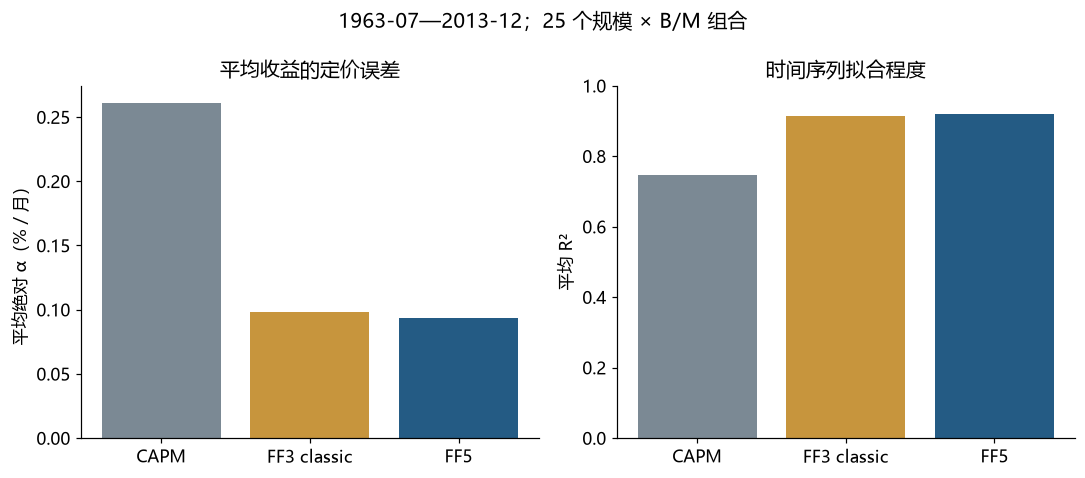

In [9]:
# 读取五因子文件，先比较两份文件中同名列的差异，再做三模型比较。
ff5 = load_returns("ff5", START, END)
assert ff5.index.equals(ff3.index)
assert np.allclose(ff5["RF"], ff3["RF"])
shared_column_diff_bp = (ff3[["RF", "Mkt-RF", "SMB", "HML"]]
                         - ff5[["RF", "Mkt-RF", "SMB", "HML"]]).abs() * 10000
display(pd.DataFrame({
    "两文件平均绝对差（bp）": shared_column_diff_bp.mean(),
    "两文件最大绝对差（bp）": shared_column_diff_bp.max()
}).round(4))
names3 = ["Mkt-RF", "SMB", "HML"]
models = {
    "CAPM": ff3[["Mkt-RF"]],
    "FF3 classic": ff3[names3],
    "FF5": ff5[[*names3, "RMW", "CMA"]]
}
# model_summary：对每个资产做含截距 OLS，汇总 α、R²，并计算经典 GRS（见 5.1–5.3 节）。
# 输入的 excess 已经减过 RF，函数不会再减一次。
comparison = model_summary(excess, models)
labels = {
    "mean_abs_alpha_pct_month": "平均绝对α（%/月）",
    "rms_alpha_pct_month": "α均方根（%/月）",
    "mean_r2": "平均R²",
    "grs_stat": "经典GRS统计量",
    "grs_pvalue": "GRS的p值",
    "T": "月份数T", "N": "资产数N", "K": "因子数K"
}
display(comparison.rename(columns=labels).style.format(precision=4, formatter={
    "GRS的p值": "{:.3g}", "月份数T": "{:.0f}",
    "资产数N": "{:.0f}", "因子数K": "{:.0f}"
}))
save_table(comparison, "PRELUDE_model_comparison")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
colors = ["#7b8994", "#c7953d", "#245b84"]
axes[0].bar(comparison.index, comparison["mean_abs_alpha_pct_month"], color=colors)
axes[0].set_ylabel("平均绝对 α（% / 月）")
axes[0].set_ylim(bottom=0)
axes[0].set_title("平均收益的定价误差")
axes[1].bar(comparison.index, comparison["mean_r2"], color=colors)
axes[1].set_ylabel("平均 R²")
axes[1].set_ylim(0, 1)
axes[1].set_title("时间序列拟合程度")
fig.suptitle("1963-07—2013-12；25 个规模 × B/M 组合")
fig.tight_layout()
plt.show()

In [10]:
c, t, v = [comparison.loc[name] for name in ["CAPM", "FF3 classic", "FF5"]]
display(Markdown(
    f"**读结果：** 从 CAPM 到 FF3 再到 FF5，平均绝对 α 依次为 **{c['mean_abs_alpha_pct_month']:.4f}**、"
    f"**{t['mean_abs_alpha_pct_month']:.4f}**、**{v['mean_abs_alpha_pct_month']:.4f}% / 月**；"
    f"平均 $R^2$ 依次为 **{c['mean_r2']:.3f}**、**{t['mean_r2']:.3f}**、**{v['mean_r2']:.3f}**。"
    "加入规模和价值因子后，定价误差和未解释波动都明显下降；这是这 25 个组合在本样本内的证据。"
    "每个模型的 GRS p 值检验的是它自己的 α 是否全为零，比较模型时以 α 的量级为主。"))

**读结果：** 从 CAPM 到 FF3 再到 FF5，平均绝对 α 依次为 **0.2613**、**0.0979**、**0.0939% / 月**；平均 $R^2$ 依次为 **0.748**、**0.913**、**0.919**。加入规模和价值因子后，定价误差和未解释波动都明显下降；这是这 25 个组合在本样本内的证据。每个模型的 GRS p 值检验的是它自己的 α 是否全为零，比较模型时以 α 的量级为主。

### 5.5 Fama–MacBeth 两步法：暴露获得了多少补偿？

前面的时间序列回归，对**同一个资产的不同月份**做回归，估出 α 和 β。Fama–MacBeth（1973）换一个角度：在**同一个月比较不同资产**，问“β 高一单位的资产，收益平均高多少”。这个“每单位 β 的补偿”就是风险价格 λ。

**第一步：估计暴露。** 对每个资产 $i$，只用月份 $t$ 之前的历史窗口 $\mathcal W_{t-1}$（例如过去 60 个月）做时间序列回归：

$$
R^e_{i,s}=a_{i,t-1}+\sum_{k=1}^K b_{i,k,t-1}f_{k,s}+e_{i,s},
\qquad s\in\mathcal W_{t-1}.
$$

$s$ 是窗口内的月份，$a$ 是截距，$b$ 是斜率，$e$ 是误差。把斜率估计记为 $\hat\beta_{i,k,t-1}$；下标 $t-1$ 表示它只用到了 $t$ 月之前已知的信息，避免前视偏差。

**第二步：每月做一次横截面回归。** 在月份 $t$，把 $N$ 个资产的当月超额收益对它们的暴露回归：

$$
R^e_{i,t}=\lambda_{0,t}+\sum_{k=1}^K\hat\beta_{i,k,t-1}\lambda_{k,t}+u_{i,t},
\qquad i=1,\ldots,N.
$$

$\lambda_{k,t}$ 是这个月第 $k$ 种暴露的“价格”，$\lambda_{0,t}$ 是横截面截距（所有资产共用，不同于每个资产自己的 $\alpha_i$），$u_{i,t}$ 是误差。

**第三步：对时间取平均。** 设第二步共有 $T_2$ 个月，风险价格估计为

$$\hat\lambda_k=\frac1{T_2}\sum_{t}\hat\lambda_{k,t}.$$

它的标准误直接用 $\hat\lambda_{k,t}$ 这条月度序列的波动来算，需要时再做 HAC 调整。还有一个问题要知道：第一步的 β 本身是估计值，带有误差，会让第二步的标准误偏小，甚至使斜率偏向零；HAC 解决不了这一点，需要 Shanken（1992）修正等专门方法。第 06 关会实际运行这套方法。

### 5.6 风险价格 λ，以及它和特征回归的区别

在线性定价模型里，资产的预期超额收益等于各暴露乘以对应风险价格：

$$\mu_i^e=\lambda_0+\sum_{k=1}^K\beta_{i,k}\lambda_k.$$

$\lambda_k$ 是第 $k$ 种暴露每增加一单位所要求的**预期超额收益补偿**。截距 $\lambda_0$ 理论上应为零：无风险资产的暴露和超额收益都是零，正确的模型应该给它定出零。用有限的风险资产估计时，$\hat\lambda_0$ 可能明显偏离零，这通常提示模型或测试资产有问题。

**可交易因子的特殊性质：** 如果因子 $f_k$ 本身就是一个零成本组合的收益（如 SMB），并且模型能正确给这些因子组合自己定价，那么因子对自己的 β 是 1、对其他因子的 β 是 0，代入上式立刻得到 $\lambda_k=E[f_{k,t}]$：**风险价格等于因子的预期收益**。这为 Fama–MacBeth 估计提供了一个对照：$\hat\lambda_k$ 应该和因子的样本均值接近。消费增长这类非交易因子没有这个性质。

**特征回归不同。** 如果第二步右边放的是公司特征而不是 β：

$$R^e_{i,t}=c_t+\gamma^{\mathrm{char}}_t z_{i,t-1}+v_{i,t},$$

$z_{i,t-1}$ 是投资前已知的特征（例如市值对数或 B/M），$\gamma^{\mathrm{char}}_t$ 是特征的月度斜率（上标 char 表示 characteristic，与风险厌恶系数 $\gamma$ 区分）。它衡量的是“特征与后续收益的关系”，单位取决于特征的量纲。要把它解读成风险补偿，还需要说明这个特征代表哪种风险暴露——这正是 FF1993 把特征变成因子、再估计暴露的原因。

### 5.7 α 变小之后：还需要回答“为什么”

新增因子让 α 变小，说明这些因子收益里包含了能解释测试资产平均收益的信息。但同样的回归改善可以来自多种机制：

- **风险补偿**：因子代表投资者确实害怕的风险；
- **错误定价**：因子捕捉的是投资者的系统性偏差；
- **特征代理**：因子与真正起作用的某个特征相关；
- **数据挖掘**：因子是在同一批数据上反复试出来的。

区分它们需要回归之外的证据：因子在哪些经济状态下表现差？谁在承担这些风险？套利受限时效应是否更强？在没参与构造因子的资产、以及事先留出的时期上，结果是否依然成立？所以写结论时，“模型在这些资产上拟合得好”和“找到了机制”要分开说。

### 5.8 统一视角：随机折现因子 SDF

前面的 CAPM、ICAPM、CCAPM、因子模型都可以放进一个统一框架。

**SDF（Stochastic Discount Factor，随机折现因子）** $m_{t+1}$ 把未来的支付换算成今天的价值。和普通折现不同，它在不同的经济状态下取值不同：同样 1 元钱，在经济困难时更值钱，$m$ 就更高。对今天价格为 $p_t$、下一期总支付为 $X_{t+1}$（卖出所得加期间分红）的资产：

$$p_t=E_t[m_{t+1}X_{t+1}].$$

$E_t[\cdot]$ 表示用 $t$ 时已有信息形成的条件期望。

**$m$ 从哪来？** 在一类标准消费模型中，

$$m_{t+1}=\delta\frac{u'(C_{t+1})}{u'(C_t)}.$$

$C_t$ 是消费量，$u(C)$ 是消费带来的效用，$u'(C)$ 是多一单位消费带来的额外效用（边际效用），$\delta$ 是对未来的时间折扣系数（不是回归 β）。边际效用递减意味着：消费越少时，多一元越珍贵，$m$ 越高。

**从 SDF 到预期收益。** 令 $\mathcal R_{i,t+1}=X_{i,t+1}/p_{i,t}$ 为**总回报倍数**（赚 5% 时等于 1.05），定价式变为 $E_t[m_{t+1}\mathcal R_{i,t+1}]=1$。设无风险总回报为 $\mathcal R_f$，超额收益 $r^e_{i,t+1}=\mathcal R_{i,t+1}-\mathcal R_{f,t+1}$，可以推出

$$E_t[r^e_{i,t+1}]=-\frac{\operatorname{Cov}_t(m_{t+1},r^e_{i,t+1})}{E_t[m_{t+1}]}.$$

**这就是全课的核心逻辑：** 在困难时期（$m$ 高）表现好的资产像保险，与 $m$ 正相关，预期收益较低；在困难时期也亏钱的资产与 $m$ 负相关，需要更高的预期收益作补偿。CAPM 用市场收益刻画“困难时期”，CCAPM 用消费增长，多因子模型用几个因子的组合——它们是对同一个 $m$ 的不同近似。

延伸阅读：[Cochrane 2011，Discount Rates](https://www.johnhcochrane.com/research-all/discount-rates)。

<a id="zoo"></a>

## 6. 因子 zoo：候选因子太多之后

### 6.1 2011 年以后的主要文献

到 2010 年代，文献中报告过能预测收益的变量已有数百个。Cochrane 把这种局面称为 **factor zoo（因子动物园）**：候选因子繁多、彼此相关，而且很多是在同一批数据上反复搜索出来的。研究重心从“发现新因子”转向“筛选和验证”。

| 文献 | 新问题 | 实操含义 |
|---|---|---|
| [Cochrane 2011，Discount Rates](https://www.johnhcochrane.com/s/discount_rates_jf.pdf) | 这么多规律能否用少数折现率因素统一解释？ | 新因子要说明它提供了哪些已有因子没有的信息 |
| [Harvey–Liu–Zhu 2016](https://people.duke.edu/~charvey/Research/Published_Papers/P118_and_the_cross.PDF) | 大量候选因子的多重检验 | 建议新因子的 t 值门槛提高到约 3 |
| [Hou–Xue–Zhang 2020，Replicating Anomalies](https://doi.org/10.1093/rfs/hhy131) | 用统一规则复查数百个异象 | 控制微盘股、改用市值加权后，大量异象不再显著 |
| [Gu–Kelly–Xiu 2020](https://dachxiu.chicagobooth.edu/download/ML.pdf) | 用机器学习处理高维、非线性的预测变量 | 严格分离训练、验证、测试样本 |
| [Open Source Asset Pricing](https://www.openassetpricing.com/) | 公开信号定义和代码 | 复现时记录定义与数据版本 |

### 6.2 读懂 zoo 研究的评价用语

- **异象**：相对于某个基准模型，尚未被解释的收益规律。换了基准模型，异象清单也会变。
- **多重检验**：同时或反复检验许多候选变量。试 100 个毫无作用的变量，按 5% 显著性水平平均也会有 5 个“显著”，所以门槛需要提高。
- **样本外**：用没有参与选择模型的数据来评价模型。常见做法是按时间切成三段：**训练集**用来估计参数，**验证集**用来选择设定，**测试集**只在最后用一次做评价。

这些检查都在回答同一个问题：新变量提供的信息，换一批数据还能重复出现吗？

### 6.3 自己做一次多因子实证的清单

1. **固定研究问题。** 是检验平均收益、预测未来收益，还是评价基金业绩？事先写下样本、测试资产和模型。
2. **只用当时可得的信息。** 财年结束日不等于财报公布日；处理退市收益、证券代码链接和存活者偏差（只保留存活至今的公司会高估收益）。
3. **写明分组规则。** 断点用哪些股票？独立分组还是条件分组？多久再平衡？等权还是市值加权？
4. **写明因子定义。** 多头、空头、规模控制、权重和数据版本；同名因子的实现可能不同。
5. **安排独立的检验对象。** 除了构造因子用的组合，再加入没参与挑选因子的资产，以及事先留出的时期。
6. **同时报告量级和不确定性。** α、标准误、联合检验、样本量、单位一起给出。
7. **主动寻找反例。** 换资产、换时期、剔除微盘股、考虑交易成本，成功和失败都记录下来。

本地的 French 官方数据足以复算因子构造、回归和联合检验；从个股原始数据开始的完整数据工程（第 2 步的大部分）是更深一层的复现。参见 [French 官方数据库与定义](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)。

<a id="crypto"></a>

## 7. 加密资产支线：同一套方法，换一个市场

股票因子的研究方法能否用到加密货币上？加密资产没有账面权益和会计利润，所以要先重新定义变量。本部分依次介绍币种数据、加密三因子的构造、加密“价值”的定义，最后是两篇代表性论文。

### 7.1 先认识一行币种数据

令 $i$ 表示币种，$t$ 表示组合形成时点，$t+1$ 表示随后的持有期。所有用于分组的特征都必须在 $t$ 时已经可以观察，要解释的是之后的收益。

| 变量 | 定义与单位 | 经济含义与用途 |
|---|---|---|
| 价格 price，$P_{i,t}$ | 时点 $t$ 每枚代币的美元价格（美元/枚） | 计算投资回报。单价受代币计量单位影响，单价低不代表便宜。需注明交易所或聚合报价及取价时点 |
| 流通量 circulating supply，$Q_{i,t}$ | 数据商估计的公众流通代币数量（枚） | 与总发行量、最大供给量不同；锁仓和团队持仓的处理取决于数据商 |
| 流通市值 market capitalization，$M_{i,t}=P_{i,t}Q_{i,t}$ | 美元 | 衡量币种规模、计算组合权重，作用相当于股票的 ME |
| 完全稀释估值 FDV（Fully Diluted Valuation） | CoinMarketCap 口径为“价格 × 最大供给量”（美元） | 假设全部代币都已发行时的估值，与流通市值回答不同问题，不用于规模分组 |
| 成交量 volume | 一段时间内的成交量；需确认单位是“枚”还是“美元” | 衡量交易活跃程度，与流动性相关。若字段已是美元成交额，不要再乘一次价格 |
| 滞后动量 $mom^{(L)}_{i,t}=P_{i,t}/P_{i,t-L}-1$ | 截至 $t$ 的过去 $L$ 期累计价格收益（小数） | 衡量近期赢家和输家，检验价格趋势是否延续 |

若一期为一周，$L=3$ 就是过去三周；随后一周的收益是 $R_{i,t+1}=P_{i,t+1}/P_{i,t}-1$。**分组用前者，评价用后者。** 在 Python 中要先按币种和时间排序，再在每个币种内部计算滞后窗口，不能让不同币种共用一条滚动序列。这里的价格收益不含质押奖励、空投等额外分配。

选价格、市值、成交量作为起点，是因为它们在所有币种上都能观察到，而公司的账面权益、利润等会计量在币市里没有直接对应物。

来源：[CoinMarketCap 供给口径说明](https://support.coinmarketcap.com/hc/en-us/articles/360043396252-Supply-Circulating-Total-Max)；[LTW 2019 作者稿，第 2—3 节](https://cowles.yale.edu/sites/default/files/2022-10/LiuTsyvinskiWu2019%20COMMON%20RISK%20FACTORS.pdf)。

### 7.2 加密三因子 CMKT、CSMB、CMOM 怎样构造

和股票一样，**因子收益是一个组合在某期实现的收益，而不是币种的某个特征**。多空因子的收益是“等金额买入多头、卖空空头”的收益差；实际操作还涉及借币成本、交易成本和保证金。

| 论文记号 | 本地文件列名 | 定义 | 为什么选这个方向 |
|---|---|---|---|
| CMKT（cryptocurrency market factor，币市因子） | `cmkt` | 币市组合收益减同期无风险收益 $R_f$（原稿用 1 个月美国国库券利率） | 捕捉币市整体的共同涨跌。比特币只是其中一个币，不能代表整个市场 |
| CSMB（cryptocurrency small minus big，币市规模因子） | `csize` | 小市值币组合收益减大市值币组合收益 | 检验币种规模差异能否补充市场因子 |
| CMOM（cryptocurrency momentum factor，币市动量因子） | `cmom` | 过去高收益币组合收益减过去低收益币组合收益 | 检验近期赢家与输家的收益差 |

**具体做法（2019 年 4 月 15 日作者稿，第 4 节）：** 每周分别按市值和过去三周收益分组，各分成最低 30%、中间 40%、最高 30% 三组，组内市值加权；CSMB 取小减大，CMOM 取高动量减低动量。这是两次**单独**分组，和股票 FF 的 2×3 交叉分组不同。作者在脚注中说明，选三周窗口是因为它在其样本中的多空价差最大——这是一个基于样本的选择。

[2019 原稿，印刷第 15—16 页（PDF 第 16—17 页）](https://cowles.yale.edu/sites/default/files/2022-10/LiuTsyvinskiWu2019%20COMMON%20RISK%20FACTORS.pdf#page=16)；正式版见 [2022 Journal of Finance](https://onlinelibrary.wiley.com/doi/full/10.1111/jofi.13119)，具体参数以正式版为准。

**使用本地数据前要注意两点：** 作者工作簿没有标明收益单位（小数还是百分数），所以本课保留原值，不做缩放；CSMB、CMOM 是多空收益差，无风险收益已经相消，不应再减 $R_f$，而月度的无风险收益也不能直接从周度收益中减去。

### 7.3 没有账面权益，怎样定义加密“价值”

**活跃地址数**（active addresses）是一个时间窗口内发生过指定链上活动的不同地址数量，单位为“个地址”。“活跃”的条件依数据源和区块链而定；例如 Coin Metrics 按参与账本变动统计，并在窗口内去重。所以 7 天的活跃地址数不等于 7 个日数据相加——同一个地址可能每天都出现。参见 [Coin Metrics 定义](https://docs.coinmetrics.io/network-data/network-data-overview/addresses/active-addresses)。

Cong 等（MS 2026）正式摘要中的**加密价值特征**是

$$\text{活跃地址数}/\text{币种市值}.$$

**经济含义：** 股票的 B/M 比较“会计价值”和“市场价格”；这里比较的是“链上使用量”和“市场价格”。比率高，说明相对于市场给出的估值，网络上有更多实际使用，类似于“相对使用量更便宜”。

**复算时需要固定的参数：** 地址统计窗口及其结束时点、币种范围、市值的计价货币，并按同一形成时点对齐（市值是时点存量，地址数是窗口流量）。若市值以美元计，比率单位是“地址/美元”。正式版的精确窗口、汇总方法和组合断点本课尚未核实，因此只介绍定义，不预设这些参数。

**测量误差的来源：** 一个用户可以控制多个地址，一个交易所地址可以代表许多用户，活动也可以由程序刷出来；地址数更不等于持币人的现金流。

论文的另一个主题是**市场分割**（market segmentation）：不同资产群体之间的投资、信息或交易联系不充分，使得同一种风险在不同群体中可能得到不同的补偿。作者按代币的经济功能分组来检验这一点；仅凭“类别不同”或“收益相关性低”还不足以证明分割。参见 [Cong 等，MS 2026](https://pubsonline.informs.org/doi/10.1287/mnsc.2024.05875)。

### 7.4 两篇代表性论文

| 文章 | 发表信息 | 模型 |
|---|---|---|
| Liu、Tsyvinski、Wu，*Common Risk Factors in Cryptocurrency* | [Journal of Finance，2022](https://doi.org/10.1111/jofi.13119) | 币市市场、规模、动量三因子 |
| Cong、Karolyi、Tang、Zhao，*Crypto Value, Factor Pricing, and Market Segmentation* | [Management Science，2026-06-05 在线发表](https://doi.org/10.1287/mnsc.2024.05875) | 上述三个因子加加密价值，共四因子 |

JF 三因子沿用股票研究的套路：先找出按特征分组后的收益差异，再用少数几个因子解释它们。它和股票 FF3 一样有市场和规模，但第三个因子是动量而不是价值：

$$
R^e_{i,t}=\alpha_i+\beta_{i,M}CMKT_t+\beta_{i,S}CSMB_t
           +\beta_{i,U}CMOM_t+\varepsilon_{i,t}.
$$

| 因子 | 构造思想 | 需要区分的对象 |
|---|---|---|
| CMKT | 广泛币种的市值加权超额收益 | 比特币收益不是整个币市收益 |
| CSMB | 小市值币减大市值币 | 币种的市值是特征，对 CSMB 的回归斜率是暴露 |
| CMOM | 过去赢家减过去输家 | 分组用过去信息，收益在之后发生 |

这里的“市场”只包含加密资产。标准 CAPM 的市场组合包括所有风险资产，所以币市单因子更适合理解为“币市内部的基准”，解释时要考虑币市与其他市场的分割。[作者 2019 年公开稿](https://economics.yale.edu/sites/default/files/2022-10/LiuTsyvinskiWu2019%20COMMON%20RISK%20FACTORS.pdf) 展示了构造和检验思路，具体数字以 2022 年正式版为准。

### 7.5 这条支线怎样做实证

**JF 2022 的步骤：** 整理当时可观察的币种价格、市值和成交量 → 按特征分组 → 计算随后持有期的多空收益 → 比较只有 CMKT 与加入 CSMB、CMOM 后的 α。正式摘要报告，三因子模型解释了作者识别出的十个显著策略。

**MS 2026 的扩展：** 用“活跃地址数 / 市值”刻画加密价值，加入价值因子，并研究不同功能代币之间的市场分割。作者提出，价值溢价可能是对链上活动风险的补偿。参见 [正式发表记录与摘要](https://pubsonline.informs.org/doi/10.1287/mnsc.2024.05875)。

**迁移到新市场时要重新处理的问题：** 代理变量到底测量什么（地址 ≠ 用户 ≠ 现金流）；活跃度怎样计量；币种的功能分类；退市和失去流动性的币（相当于股票的存活者偏差）；能否做空；交易成本有多高。

**全课的方法链条：**
CAPM 的市场协方差 → FF 的特征分组与多因子检验 → 加密市场 / 规模 / 动量 → 链上价值与市场分割。
每一环都要分别回答三个问题：能否拟合共同波动？能否解释平均收益？背后的经济机制是什么？

### 7.6 本地加密数据：读取与核验

作者在 [研究主页](https://www.yukunliu.com/research/) 公开了三因子数据。本地材料与股票数据分开存放：
[原始工作簿](../data/crypto_raw/LTW_3factor.xlsx)、[CSV 原值](../data/crypto_raw/LTW_3factor_raw_values.csv)、[来源与核验清单](../data/crypto_raw/manifest.json)、[2019 作者工作稿](../papers/crypto/LTW_working_paper_20190415.pdf)。

下面一格读取 CSV，核对文件哈希、列名和周序号的连续性，并显示前几行。几点背景：

- 工作簿说明写“更新至 2022”，实际末行是 2023 年第 14 周；
- 收益单位没有标注，因此保留原值，只做读取和日期核验，不做定价回归；
- 我们手里只有因子收益，没有币种层面的测试资产，所以还不能检验这些因子的定价能力（把因子对自己回归没有意义）。

MS 2026 的附录和数据附件见 [官方页面](https://pubsonline.informs.org/doi/suppl/10.1287/mnsc.2024.05875)，本课尚未取得核验。其 2022 年公开稿曾使用五因子版本，本课采用 2026 正式摘要的四因子定义。

In [11]:
import hashlib
import json
crypto_dir = ROOT / "data/crypto_raw"
crypto_meta = json.loads((crypto_dir / "manifest.json").read_text(encoding="utf-8"))
raw_csv = crypto_dir / crypto_meta["derived_csv"]["filename"]
assert hashlib.sha256(raw_csv.read_bytes()).hexdigest() == crypto_meta["derived_csv"]["sha256"]
# 以字符串读取，保留作者文件中的原始数值写法；单位确认之前不做数值换算。
crypto_raw = pd.read_csv(raw_csv, dtype=str)
assert list(crypto_raw.columns) == ["yyww", "cmkt", "csize", "cmom"]
assert crypto_raw["yyww"].is_unique and not crypto_raw.isna().any().any()
week_code = crypto_raw["yyww"].astype(int)
assert (week_code % 100).between(1, 52).all()
author_week = (week_code // 100) * 52 + week_code % 100
assert author_week.diff().dropna().eq(1).all()
display(crypto_raw.head())
print(f"作者表：{len(crypto_raw)} 周；首末周标识 {week_code.iloc[0]}—{week_code.iloc[-1]}，周序号连续。")
print("周历：作者每年固定编 52 周，年末最后一周超过 7 天，因此与 ISO 周编号不同。")
print("单位：作者文件未标注，表中为原始数值。")
print("数据源：据作者说明，2020 年中起改用 CoinGecko，后期数据是对原发表样本的扩展。")

,yyww,cmkt,csize,cmom
0,201404,-6.5000000000000002E-2,-0.02,-0.27
1,201405,1.7000000000000001E-2,-4.9000000000000002E-2,-2.5999999999999999E-2
2,201406,-0.184,-0.03,0.14199999999999999
3,201407,-7.0999999999999994E-2,0.108,0.13800000000000001
4,201408,-0.14199999999999999,-8.6999999999999994E-2,-9.8000000000000004E-2


作者表：479 周；首末周标识 201404—202314，周序号连续。
周历：作者每年固定编 52 周，年末最后一周超过 7 天，因此与 ISO 周编号不同。
单位：作者文件未标注，表中为原始数值。
数据源：据作者说明，2020 年中起改用 CoinGecko，后期数据是对原发表样本的扩展。


## 8. 变量速查与下一步

### 8.1 变量速查

| 你在表格或代码中看到的量 | 回到哪一部分 |
|---|---|
| R、RF、超额收益、期望、样本均值、方差、协方差 | [1. 收益与统计记号](#returns) |
| CAPM、市场组合、β、α、残差、OLS、风险厌恶 | [2. 市场 β 与 CAPM](#capm) |
| 25 组合、测试资产、`Mkt-RF` 等数据列 | [2.5 读入真实数据](#real-data) |
| BE、ME、B/M、P/B、S/B、L/N/H、SMB、HML、λ 的初步含义 | [3. 从异象到三因子](#ff3) |
| OP、Inv、RMW、CMA、GP/A、Mom、q 模型 | [4. 盈利、投资与动量](#ff5) |
| T/N/K、$R^2$、标准误、t 值、p 值、HAC、GRS、Fama–MacBeth、λ、SDF | [5. 怎样检验一个因子模型](#model-tests) |
| 异象、多重检验、样本外 | [6. 因子 zoo](#zoo) |
| 币市市值、成交量、动量、CMKT、CSMB、CMOM、活跃地址 / 市值 | [7. 加密资产支线](#crypto) |

原论文的表号和样本口径可在 [论文表格导航](../papers/TABLE_GUIDE.md) 中查找。

### 8.2 接下来读哪一关

- 市场 β：[第 01 关](01_risk_and_capm.ipynb)、[第 03 关](03_capm_test.ipynb)。
- 特征到因子：[第 04 关](04_build_ff3.ipynb)、[第 07 关](07_build_ff5.ipynb)。
- 复现原论文表格：[第 05 关](05_ff3_replication.ipynb)、[第 08 关](08_ff5_replication.ipynb)，配合 [论文表格导航](../papers/TABLE_GUIDE.md)。
- β 与风险价格：[第 06 关](06_fama_macbeth.ipynb)。
- 样本外检验：[第 09 关](09_out_of_sample.ipynb)。

本地原文：[FF1993](../papers/ff1993_primary_reference.pdf)、[FF2015](../papers/ff2015_primary_reference.pdf)。不必读完全部文献再动手，带着每关的问题去翻相关表格更有效。

## Boss 作答区

先写下自己的预判，再设计检查。这里不预填答案。

1. 换一个市场指数作代理，哪些统计量会变化？你的结论适用范围要怎样表述？
2. 发现某个特征分组的组合平均收益很高后，需要哪些步骤才能把它评价为候选因子？
3. 怎样改进实验 C，让“新增因子是否有效”的解释更清楚？

<strong>你的回答：</strong>

（运行后填写，引用本导读至少一张表或图。）